##### 2-1. 합성데이터 생성
<pre style="font-size:16px">
# colab -> Colab CPU -> terminal
wget https://raw.githubusercontent.com/code-archive-git/ai/refs/heads/main/production/data/lots.csv
</pre>

In [17]:
from sklearn.preprocessing import StandardScaler
import pandas as pd
import numpy as np

df = pd.read_csv("/content/lots.csv")
df.head()

,item_00,item_01,item_02,item_03,item_04,item_05,item_06,item_07,item_08,item_09,...,item_12,item_13,item_14,item_15,item_16,item_17,item_18,item_19,lot_id,is_anomaly
0,3.350976,0.459486,0.833609,-1.198866,-0.336197,-2.112543,4.028169,2.366414,0.302036,-0.083915,...,2.058230,0.294933,-2.742144,2.052421,-2.468336,-2.022098,-1.064364,-3.365101,L00306,0
1,-0.065284,0.119303,-0.202643,0.275735,0.835242,0.245785,-0.164229,-0.233828,-0.012679,0.742391,...,-0.144031,0.022573,-0.081021,0.378786,-0.751205,0.375250,0.126565,-0.869860,L02419,0
2,-2.828491,-0.625272,-1.376907,1.004420,-0.787996,0.571938,-5.040275,-1.385274,0.313504,-0.596291,...,-1.242914,-1.651848,1.716077,-2.468195,0.302506,1.301379,-1.865949,0.328217,L02545,0
3,2.613067,0.186323,1.731213,-0.088439,0.200636,1.113511,4.086913,0.049996,0.297533,-0.040396,...,1.055709,1.799756,-0.572613,1.294069,0.571779,-1.506740,2.558498,2.205528,L01266,0
4,1.169803,0.526472,-1.190703,-2.043262,0.414965,-3.150362,3.815378,3.115319,-2.467513,1.452932,...,0.455150,0.257534,-0.458874,2.605719,-1.685924,-0.326259,-0.121298,-1.874065,L01950,0


#### 2-2. [1단계] 다변량 특징 구성

In [12]:

# item_ 으로 시작하는 컬럼을 cols 에 담는다.
# cols = [c for c in df.columns if c.startswith('item_')]
cols = []
for c in df.columns:
    if c.startswith('item_'):
        cols.append(c)
print(cols)

['item_00', 'item_01', 'item_02', 'item_03', 'item_04', 'item_05', 'item_06', 'item_07', 'item_08', 'item_09', 'item_10', 'item_11', 'item_12', 'item_13', 'item_14', 'item_15', 'item_16', 'item_17', 'item_18', 'item_19']


In [ ]:
normal = df[df['is_anomaly'] == 0]  # 정상인 데이터만 따로 normal 에 담는다.
# normal.head()
train = normal.sample(2000, random_state=0) # 정상 로트 2,000개를 무작위 샘플링해 train 에 둔다
eval_df = df.drop(train.index) # train 에 해당하는 index 를 찾아 데이터 삭제(나머지 검증용 데이터)
# eval_df.head()


,item_00,item_01,item_02,item_03,item_04,item_05,item_06,item_07,item_08,item_09,...,item_12,item_13,item_14,item_15,item_16,item_17,item_18,item_19,lot_id,is_anomaly
0,3.350976,0.459486,0.833609,-1.198866,-0.336197,-2.112543,4.028169,2.366414,0.302036,-0.083915,...,2.058230,0.294933,-2.742144,2.052421,-2.468336,-2.022098,-1.064364,-3.365101,L00306,0
3,2.613067,0.186323,1.731213,-0.088439,0.200636,1.113511,4.086913,0.049996,0.297533,-0.040396,...,1.055709,1.799756,-0.572613,1.294069,0.571779,-1.506740,2.558498,2.205528,L01266,0
7,0.553963,0.194883,0.379142,0.670746,0.367509,0.491417,0.897930,-0.712592,0.848161,1.206640,...,0.597966,0.370232,-1.042950,0.003022,0.406565,-0.198239,1.230180,-0.851434,L01056,0
12,-1.151463,0.430967,-2.125647,-0.696642,1.075176,-2.911351,-0.738585,1.450194,-0.890445,1.618003,...,-0.416466,-1.693202,0.198748,0.568770,-2.021709,0.682167,-0.656358,-2.653704,L02529,0
17,-1.803585,-0.240139,-0.488106,2.769041,1.502309,2.502286,2.462527,2.258963,-2.383748,-1.348869,...,-0.567592,0.347812,1.383741,1.834457,-0.826135,-1.082885,-0.070953,1.791031,L03026,1


In [21]:

# 학습 데이터 정규화
sc = StandardScaler().fit(train[cols])

# 학습·평가 데이터 모두 같은 스케일러 기준(sc)으로 변환
Xs_train = sc.transform(train[cols])
Xs_eval = sc.transform(eval_df[cols])

# 정답 꺼내기
y_eval = eval_df['is_anomaly'].values

In [28]:
# 단변량 규격 판정으로는 잡히는가?
# np.abs(Xs_eval) < 3.5 # Xs_eval 값을
# .all(axis=1) # row 단위로 봤을때 전체  True 인지 검사

# 3.5는 StandardScaler 기준 표준편차 3.5배(±3.5σ)를 단변량 규격선으로 둔 임의 기준값
in_spec = (np.abs(Xs_eval) < 3.5).all(axis=1)
# print(in_spec)
print('이상 로트 중 규격 통과 비율 :', in_spec[y_eval == 1].mean())

이상 로트 중 규격 통과 비율 : 1.0


In [ ]:
#### 2-3. [2단계] AutoEncoder / IForest 학습

In [30]:
from sklearn.decomposition import PCA
from sklearn.neural_network import MLPRegressor
from sklearn.ensemble import IsolationForest

# 1) PCA (복원 기준선)
# n_components=0.9: 전체 정상 데이터(Xs_train) 분산의 90% 이상을 설명할 수 있는 최소 개수의 주성분 축 생성
pca = PCA(n_components=0.9).fit(Xs_train)

# 2) AutoEncoder : 16-4-16 히든레이어 생성
# early_stopping=True: 내부 검증 손실이 더 이상 개선되지 않으면 3,000회 전이라도 학습을 조기 종료해 과적합을 방지
ae = MLPRegressor(hidden_layer_sizes=(16, 4, 16), activation='relu',
                  max_iter=3000, early_stopping=True, random_state=0)
ae.fit(Xs_train, Xs_train)

# 3) Isolation Forest
iso = IsolationForest(n_estimators=300, random_state=0).fit(Xs_train)

#### 2-4. [3단계] 재구성오차 스코어링

In [ ]:
from sklearn.metrics import roc_auc_score

# 모델(model), 평가 입력 데이터(X), 모델 종류 문자열(kind)을 받아 재구성 오차를 반환
def recon_err(model, X, kind):
    R = None
    if kind == 'pca': # kind == 'pca'인 경우
        # model.transform(X)로 주성분 공간에 압축
        # model.inverse_transform(...)으로 원래 20차원 공간으로 되돌린 복원값 R에 담는다.
        R = model.inverse_transform(model.transform(X))
    else: # 그 외(ae, AutoEncoder)
        # model.predict(X)로 신경망(20 → 16 → 4 → 16 → 20)을 거쳐 복원된 값을 R에 담는다.
       R = model.predict(X)
    # 입력 데이터와 R 의 오차 값을 row 방향으로 평균을 낸 값,
    # 로트별·항목별 제곱 오차가 그대로 담긴 2차원 배열
    return ((X - R) ** 2).mean(axis=1), (X - R) ** 2

# print(recon_err(pca, Xs_eval, 'pca')[0])
# print(recon_err(ae,  Xs_eval, 'ae')[0])
# print(-iso.decision_function(Xs_eval))


[0.10062471 0.04525209 0.01590788 ... 0.02377492 0.02105069 0.01712645]
[0.09985372 0.04570191 0.01681133 ... 0.02346899 0.02160813 0.0169441 ]
[-0.01516131 -0.08614531 -0.12572434 ... -0.09223723 -0.10720674
  0.0655991 ]


In [36]:
scores = {
    'PCA'            : recon_err(pca, Xs_eval, 'pca')[0],
    'AutoEncoder'    : recon_err(ae,  Xs_eval, 'ae')[0],
    'IsolationForest': -iso.decision_function(Xs_eval),
}

# 실행된 내용을 name 과 점수를 산출하여 roc_auc_score() 로 점수를 낸다.
for name, s in scores.items():
    # roc_auc_score() : 모델이 매긴 연속적인 이상 점수(y_score)가 실제 정답을 얼마나 잘 구분하는지 평가
    # 범위 : 0~1 사이
    print(f'{name:16s} ROC-AUC = {roc_auc_score(y_eval, s):.3f}')

PCA              ROC-AUC = 0.964
AutoEncoder      ROC-AUC = 0.964
IsolationForest  ROC-AUC = 0.634


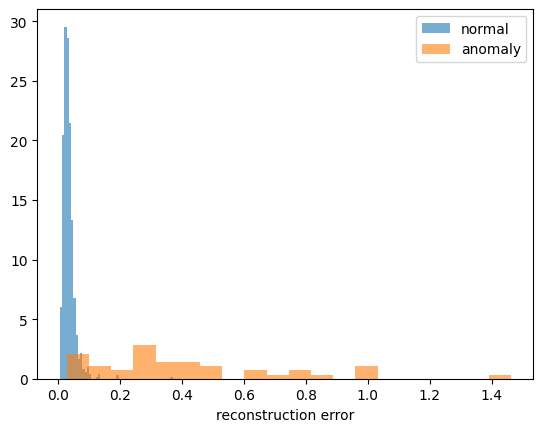

In [ ]:
# 재구성오차 분포 (산출물)
s = scores['AutoEncoder']
# density=True로 각 집단의 전체 면적을 1로 정규화해 분포 모양과 위치를 공정하게 비교
plt.hist(s[y_eval == 0], bins=50, alpha=0.6, label='normal', density=True)
plt.hist(s[y_eval == 1], bins=20, alpha=0.6, label='anomaly', density=True)
plt.xlabel('reconstruction error')
plt.legend()
plt.show()